# Detecção de amastigotas fora do macrófago — experimento 7 (recortes sem a região do macrófago + YOLO11-nano + aumento de dados)

- Autor: Clésio Gonçalves

## Contexto

Os experimentos 1-6 usaram os recortes **originais** (região do macrófago visível na imagem). Este experimento usa os recortes gerados em `pre_processamento_dataset_recortes_sem_macrofago.ipynb` (`dataset_recortes_macrofagos_infectados_sem_macrofago/`), nos quais:

- a região de cada bounding box `macrophage` é pintada de preto (mascarada);
- as anotações das classes `macrophage` e `inside-macrophage` são removidas do `.txt`;
- as anotações de `leishmania` (fora do macrófago — classe de interesse) e `Non-macrophages` são mantidas integralmente.

**Motivação**: como o recorte é centrado no macrófago infectado, a região do macrófago carrega as leishmanias intracelulares (`inside-macrophage`), que não são o alvo desta detecção. Mascarar essa região tende a reduzir a confusão do modelo entre leishmania intra e extracelular.

## Mudanças deste experimento

1. **Dataset sem a região do macrófago** (descrito acima), em vez dos recortes originais.
2. **YOLO11-nano** (`yolo11n.pt`, o menor modelo da família, ~2.6M parâmetros) — mesmo modelo do experimento 1, mas agora sobre o novo dataset.
3. **Imagens no padrão RGB original**, sem conversão de espaço de cor (diferente dos experimentos 5 e 6, que usavam CLAHE/Lab).
4. **Aumento de dados explícito** — mesma receita validada no experimento 5 (melhor recall da série): jitter de cor moderado (`hsv_h/s/v`), rotação (`degrees=15`), flip vertical (`flipud=0.5`, sem orientação canônica em microscopia) e `mixup=0.1`, além dos aumentos padrão do Ultralytics (mosaico, flip horizontal, translação, escala).
5. **150 épocas, batch=16**, `patience=40`, `cos_lr=True`, otimizador `AdamW` com `lr0=0.0005`.

Mesmos 6 folds e mesmas 8 lâminas dos experimentos anteriores (ver `divisao_dataset.jpeg`), com diagnóstico agregado por fold e também por lâmina individual.

**Nota sobre a comparação com os experimentos 1-6**: como a entrada de imagem é diferente (região do macrófago mascarada), a comparação não é "mesma entrada, mesmo modelo" — mas as lâminas, os folds e a classe-alvo (`leishmania` fora do macrófago) são idênticos, então a comparação ainda é informativa sobre o efeito conjunto de (mascarar o macrófago + nano + aumento de dados) frente às configurações anteriores.

## Resultado

**mAP50 médio: 0.4850 ± 0.1090** — o **melhor resultado agregado de toda a série** (Exp.1: 0.4391, Exp.5: 0.4345, os demais abaixo disso). O experimento 7 também venceu em **todas** as outras métricas: precisão 0.5077 ± 0.1022 (melhor anterior: Exp.1, 0.4735), recall 0.5471 ± 0.0743 (melhor anterior: Exp.5, 0.5170) e mAP50-95 0.1841 ± 0.0391 (melhor anterior: Exp.1, 0.1695). Nenhum experimento 1-6 havia liderado nas 4 métricas simultaneamente.

Todos os 6 folds pararam por *early stopping* (`patience=40`) bem antes das 150 épocas (entre a época 52 e a 103), sinal de convergência rápida e estável — provavelmente porque o mascaramento do macrófago remove uma fonte de ambiguidade visual (leishmania intra vs. extracelular) que confundia os experimentos anteriores.

**Diagnóstico por lâmina (mAP50 médio)**: melhor em `leish_7` (0.6721) e `leish_1` (0.5254); pior em `leish_4` (0.1844, único fold em que aparece) e `leish_8` (0.3589). `leish_4` permanece a lâmina mais difícil da série (também foi a pior no Exp.1, com 0.173) — consistente com poucos exemplos de leishmania extracelular nessa lâmina, independentemente do pré-processamento. Já `leish_3` — historicamente a pior lâmina em quase todos os experimentos 1-6 (mAP50 entre 0.11 e 0.36) — teve aqui 0.3591, no topo da faixa histórica dela.

**Conclusão**: a combinação (mascarar a região do macrófago + YOLO11-nano + aumento de dados geométrico/cor + batch=16/150 épocas) superou de forma consistente e simultânea em todas as métricas as seis configurações anteriores, que usavam os recortes com o macrófago visível. Isso sugere que remover a região do macrófago da imagem de entrada — e não o tamanho do modelo, o espaço de cor ou o batch size testados nos experimentos 3-6 — é o fator que mais ajudou até agora. `leish_4` continua sendo o ponto fraco estrutural da série (poucas instâncias de leishmania fora do macrófago), independente da técnica usada.


## Utilização da GPU

In [1]:
!nvidia-smi

Mon Aug 10 15:16:00 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.84                 Driver Version: 595.84         CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5070 Ti     Off |   00000000:01:00.0 Off |                  N/A |
|  0%   32C    P8             15W /  300W |      15MiB /  16303MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"


# Importações e parâmetros gerais

In [3]:
import shutil
import yaml
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2
from pathlib import Path
from PIL import Image

import torch
from ultralytics import YOLO

import warnings
warnings.filterwarnings('ignore')

# Bloqueia logs de C++ (INFO e WARNING)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_MLIR_ENABLE_MLIR_HAL_TARGET_ EXECUTABLE_DUMP_PATH'] = ''
os.environ['MLIR_CRASH_REPRODUCER_DIRECTORY'] = ''


In [4]:
# Versões dos pacotes usados neste jupyter notebook
%reload_ext watermark
%watermark -a "Clésio Gonçalves" --iversions
!python --version
!conda -V


Author: Clésio Gonçalves

PIL        : 12.0.0
cv2        : 4.13.0
matplotlib : 3.10.6
numpy      : 2.3.5
pandas     : 2.3.3
torch      : 2.12.1
ultralytics: 8.4.75
yaml       : 6.0.3

Python 3.13.9


conda 26.1.1


In [5]:
torch.cuda.is_available()

True

## Parâmetros do sistema

In [6]:
# Diretório raiz
diretorio_raiz = Path("/mnt/arquivos/Doutorado")


## Estrutura do Dataset

PROBLEMA:
  - 8 lâminas anotadas no formato YOLO
  - Classes originais (mesmo `obj.names` dos experimentos anteriores, preservado por compatibilidade mesmo com `macrophage`/`inside-macrophage` ausentes dos `.txt` deste dataset):
      0 - Non-macrophages
      1 - Macrophage (ausente nas anotações deste dataset — região mascarada de preto na imagem)
      2 - leishmania (FORA do macrófago) --> classe de interesse
      3 - Inside-macrophage (ausente nas anotações deste dataset)

  - Objetivo: detectar APENAS leishmania fora dos macrófagos (classe 2), agora com a região do macrófago mascarada na própria imagem de entrada.

![divisao_dataset.jpeg](attachment:divisao_dataset.jpeg)

## Parâmetros do experimento

In [7]:
# Diretório com os recortes (512x512) SEM a região do macrófago (mascarada de preto), gerados em pre_processamento_dataset_recortes_sem_macrofago.ipynb
diretorio_recortes = os.path.join(diretorio_raiz, "dataset_recortes_macrofagos_infectados_sem_macrofago")

# Tamanho de treino/inferência = tamanho original do recorte, sem upscaling
tamanho_imagem = 512
extensao = '.png'

# Classes do dataset de recortes (mesma ordem do obj.names)
caminho_obj_names = os.path.join(diretorio_recortes, "obj.names")
with open(caminho_obj_names) as f:
    classes_originais = [linha.strip() for linha in f]

# Apenas leishmania FORA do macrófago é a classe de interesse (single-class detector)
nome_classe_interesse = 'leishmania'
indice_classe_interesse = classes_originais.index(nome_classe_interesse)
print(f"Classes originais: {classes_originais}")
print(f"Índice de '{nome_classe_interesse}' (classe de interesse): {indice_classe_interesse}")

# Diretórios de trabalho (dataset YOLO próprio deste experimento, pois as imagens são diferentes - sem macrófago)
diretorio_yolo_folds = os.path.join(diretorio_raiz, "yolo_folds_leishmania_sem_macrofago")
diretorio_runs = os.path.join(diretorio_raiz, "runs_leishmania_kfold_yolo11n_sem_macrofago")
os.makedirs(diretorio_yolo_folds, exist_ok=True)
os.makedirs(diretorio_runs, exist_ok=True)

# Pesos pré-treinados do YOLO11-nano
caminho_pesos_pretreinados = 'yolo11n.pt'

tamanho_batch = 16

# Hiperparâmetros de treinamento
parametros_treino = dict(
    epochs=150,
    patience=40,
    imgsz=tamanho_imagem,
    batch=tamanho_batch,
    device=0,
    seed=42,
    workers=8,
    cos_lr=True,
    single_cls=True,
    verbose=False,
    optimizer='AdamW',
    lr0=0.0005,
    lrf=0.01,
    # aumento de dados (mesma receita do experimento 5): imagens em RGB puro, então o jitter de cor
    # (hsv_h/s/v) do Ultralytics é válido aqui; rotação e flip vertical habilitados (sem orientação
    # canônica em microscopia); mixup para robustez adicional. Mosaico, flip horizontal, translação e
    # escala seguem os padrões do Ultralytics (já ativos por padrão).
    hsv_h=0.03,
    hsv_s=0.9,
    hsv_v=0.6,
    degrees=15.0,
    flipud=0.5,
    mixup=0.1,
)


Classes originais: ['Non-macrophages', 'macrophage', 'leishmania', 'inside-macrophage']
Índice de 'leishmania' (classe de interesse): 2


## Definição dos 6 folds (idêntica aos experimentos anteriores, para comparação direta)

In [8]:
folds = [
    {'fold': 1, 'treino': ['leish_1', 'leish_2', 'leish_7', 'leish_8', 'leish_9'], 'validacao': ['leish_4'], 'teste': ['leish_3', 'leish_5']},
    {'fold': 2, 'treino': ['leish_1', 'leish_3', 'leish_4', 'leish_5', 'leish_9'], 'validacao': ['leish_8'], 'teste': ['leish_2', 'leish_7']},
    {'fold': 3, 'treino': ['leish_2', 'leish_3', 'leish_4', 'leish_5', 'leish_7'], 'validacao': ['leish_9'], 'teste': ['leish_1', 'leish_8']},
    {'fold': 4, 'treino': ['leish_1', 'leish_2', 'leish_3', 'leish_5', 'leish_8'], 'validacao': ['leish_7'], 'teste': ['leish_4', 'leish_9']},
    {'fold': 5, 'treino': ['leish_3', 'leish_4', 'leish_5', 'leish_8', 'leish_9'], 'validacao': ['leish_2'], 'teste': ['leish_1', 'leish_7']},
    {'fold': 6, 'treino': ['leish_3', 'leish_4', 'leish_5', 'leish_7', 'leish_9'], 'validacao': ['leish_1'], 'teste': ['leish_2', 'leish_8']},
]

pd.DataFrame(folds).set_index('fold')


,treino,validacao,teste
fold,,,
1,"[leish_1, leish_2, leish_7, leish_8, leish_9]",[leish_4],"[leish_3, leish_5]"
2,"[leish_1, leish_3, leish_4, leish_5, leish_9]",[leish_8],"[leish_2, leish_7]"
3,"[leish_2, leish_3, leish_4, leish_5, leish_7]",[leish_9],"[leish_1, leish_8]"
4,"[leish_1, leish_2, leish_3, leish_5, leish_8]",[leish_7],"[leish_4, leish_9]"
5,"[leish_3, leish_4, leish_5, leish_8, leish_9]",[leish_2],"[leish_1, leish_7]"
6,"[leish_3, leish_4, leish_5, leish_7, leish_9]",[leish_1],"[leish_2, leish_8]"


## Construção da estrutura de dataset YOLO para cada fold

In [9]:
# Filtra as anotações de um .txt YOLO, mantendo só a classe de interesse e remapeando-a para o índice 0
def remapeia_anotacoes_classe_unica(txt_origem, indice_classe_interesse):
    linhas_novas = []
    if os.path.isfile(txt_origem):
        with open(txt_origem) as f:
            for linha in f:
                linha = linha.strip()
                if not linha:
                    continue
                partes = linha.split()
                if int(partes[0]) == indice_classe_interesse:
                    linhas_novas.append("0 " + " ".join(partes[1:]))
    return linhas_novas


# Cria link simbólico de uma imagem e grava o .txt remapeado (classe única) na pasta de destino
def linka_imagem_e_anotacao(arquivo, pasta_origem, pasta_img_destino, pasta_lbl_destino, indice_classe_interesse):
    nome_base = os.path.splitext(arquivo)[0]

    img_origem = os.path.join(pasta_origem, arquivo)
    img_destino = os.path.join(pasta_img_destino, arquivo)
    if not os.path.exists(img_destino):
        os.symlink(img_origem, img_destino)

    txt_origem = os.path.join(pasta_origem, f"{nome_base}.txt")
    linhas = remapeia_anotacoes_classe_unica(txt_origem, indice_classe_interesse)
    with open(os.path.join(pasta_lbl_destino, f"{nome_base}.txt"), 'w') as f:
        f.write("\n".join(linhas))
        if linhas:
            f.write("\n")


# Monta a estrutura YOLO (images/labels) de um fold: treino, validação, teste (agregado) e teste por lâmina
def monta_dataset_fold(fold, diretorio_recortes, diretorio_yolo_folds, indice_classe_interesse, extensao):
    diretorio_fold = os.path.join(diretorio_yolo_folds, f"fold_{fold['fold']}")
    if os.path.isdir(diretorio_fold):
        shutil.rmtree(diretorio_fold)

    for papel, laminas in [('train', fold['treino']), ('val', fold['validacao']), ('test', fold['teste'])]:
        pasta_img_destino = os.path.join(diretorio_fold, 'images', papel)
        pasta_lbl_destino = os.path.join(diretorio_fold, 'labels', papel)
        os.makedirs(pasta_img_destino, exist_ok=True)
        os.makedirs(pasta_lbl_destino, exist_ok=True)

        for lamina in laminas:
            pasta_origem = os.path.join(diretorio_recortes, lamina)

            if papel == 'test':
                # subpasta individual da lâmina (usada no diagnóstico por lâmina do conjunto de teste)
                pasta_img_lamina = os.path.join(diretorio_fold, 'images', 'test_lamina', lamina)
                pasta_lbl_lamina = os.path.join(diretorio_fold, 'labels', 'test_lamina', lamina)
                os.makedirs(pasta_img_lamina, exist_ok=True)
                os.makedirs(pasta_lbl_lamina, exist_ok=True)

            for arquivo in sorted(os.listdir(pasta_origem)):
                if not arquivo.endswith(extensao):
                    continue
                linka_imagem_e_anotacao(arquivo, pasta_origem, pasta_img_destino, pasta_lbl_destino, indice_classe_interesse)
                if papel == 'test':
                    linka_imagem_e_anotacao(arquivo, pasta_origem, pasta_img_lamina, pasta_lbl_lamina, indice_classe_interesse)

    return diretorio_fold


for fold in folds:
    diretorio_fold = monta_dataset_fold(fold, diretorio_recortes, diretorio_yolo_folds, indice_classe_interesse, extensao)
    n_train = len(os.listdir(os.path.join(diretorio_fold, 'images', 'train')))
    n_val = len(os.listdir(os.path.join(diretorio_fold, 'images', 'val')))
    n_test = len(os.listdir(os.path.join(diretorio_fold, 'images', 'test')))
    print(f"Fold {fold['fold']}: treino={n_train} | validação={n_val} | teste={n_test}")


Fold 1: treino=1064 | validação=126 | teste=378


Fold 2: treino=808 | validação=353 | teste=407


Fold 3: treino=911 | validação=208 | teste=449


Fold 4: treino=954 | validação=280 | teste=334


Fold 5: treino=1065 | validação=127 | teste=376


Fold 6: treino=992 | validação=96 | teste=480


## Geração dos arquivos `data.yaml` por fold

In [10]:
# Grava o data.yaml de um fold. Se 'test_split' for informado, aponta o "test" para uma subpasta específica (lâmina única)
def gera_data_yaml(diretorio_fold, nome_classe, caminho_yaml, test_split='test'):
    conteudo = {
        'path': str(diretorio_fold),
        'train': 'images/train',
        'val': 'images/val',
        'test': f'images/{test_split}',
        'nc': 1,
        'names': {0: nome_classe},
    }
    with open(caminho_yaml, 'w') as f:
        yaml.safe_dump(conteudo, f, sort_keys=False, allow_unicode=True)
    return caminho_yaml


caminhos_yaml = {}        # data.yaml agregado (teste = todas as lâminas do fold)
caminhos_yaml_lamina = {} # data.yaml por lâmina de teste, usado no diagnóstico

for fold in folds:
    n = fold['fold']
    diretorio_fold = os.path.join(diretorio_yolo_folds, f"fold_{n}")

    caminhos_yaml[n] = gera_data_yaml(
        diretorio_fold, nome_classe_interesse,
        os.path.join(diretorio_fold, 'data.yaml'),
    )

    for lamina in fold['teste']:
        caminhos_yaml_lamina[(n, lamina)] = gera_data_yaml(
            diretorio_fold, nome_classe_interesse,
            os.path.join(diretorio_fold, f'data_test_{lamina}.yaml'),
            test_split=f'test_lamina/{lamina}',
        )

print(f"{len(caminhos_yaml)} data.yaml agregados e {len(caminhos_yaml_lamina)} data.yaml por lâmina de teste gerados.")


6 data.yaml agregados e 12 data.yaml por lâmina de teste gerados.


## Treinamento dos 6 folds (YOLO11-nano, RGB, aumento de dados, batch=16)

Treinamento local na GPU a partir do checkpoint pré-treinado `yolo11n.pt`. Caso o `best.pt` de um fold já exista, o treinamento desse fold é pulado (idempotente).

In [11]:
caminhos_best = {}

for fold in folds:
    n = fold['fold']
    nome_run = f"fold_{n}"
    caminho_best = os.path.join(diretorio_runs, nome_run, 'weights', 'best.pt')

    if os.path.isfile(caminho_best):
        print(f"Fold {n}: pesos já existem em '{caminho_best}'. Treinamento ignorado.")
    else:
        modelo = YOLO(caminho_pesos_pretreinados)
        modelo.train(
            data=caminhos_yaml[n],
            project=diretorio_runs,
            name=nome_run,
            exist_ok=True,
            **parametros_treino,
        )
        print(f"Fold {n}: treinamento concluído. Pesos em '{caminho_best}'.")
        del modelo
        torch.cuda.empty_cache()

    caminhos_best[n] = caminho_best


New https://pypi.org/project/ultralytics/8.4.117 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.75 🚀 Python-3.13.9 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 15842MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/mnt/arquivos/Doutorado/yolo_folds_leishmania_sem_macrofago/fold_1/data.yaml, degrees=15.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.03, hsv_s=0.9, hsv_v=0.6, imgsz=512, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=fold_1, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True, patience=40, perspective=0.0, plots=True, pose=12

Overriding class names with single class.


Overriding model.yaml nc=80 with nc=1



                   from  n    params  module                                       arguments                     


... (11,538 outputs left out)

                   all         96        831      0.655      0.569      0.604      0.278


Speed: 0.0ms preprocess, 0.3ms inference, 0.0ms loss, 0.4ms postprocess per image


Results saved to /mnt/arquivos/Doutorado/runs_leishmania_kfold_yolo11n_sem_macrofago/fold_6


Fold 6: treinamento concluído. Pesos em '/mnt/arquivos/Doutorado/runs_leishmania_kfold_yolo11n_sem_macrofago/fold_6/weights/best.pt'.


## Avaliação no conjunto de teste — agregada por fold

In [12]:
# Extrai as métricas de detecção relevantes de um resultado de model.val()
def extrai_metricas(resultado_val):
    rd = resultado_val.results_dict
    return {
        'precisao': rd.get('metrics/precision(B)', float('nan')),
        'recall': rd.get('metrics/recall(B)', float('nan')),
        'mAP50': rd.get('metrics/mAP50(B)', float('nan')),
        'mAP50-95': rd.get('metrics/mAP50-95(B)', float('nan')),
    }


linhas_metricas_fold = []

for fold in folds:
    n = fold['fold']
    modelo = YOLO(caminhos_best[n])
    resultado = modelo.val(data=caminhos_yaml[n], split='test', imgsz=tamanho_imagem, plots=False, verbose=False)

    metricas = extrai_metricas(resultado)
    metricas['fold'] = n
    metricas['laminas_teste'] = ", ".join(fold['teste'])
    linhas_metricas_fold.append(metricas)

df_metricas_fold = pd.DataFrame(linhas_metricas_fold).set_index('fold')
df_metricas_fold = df_metricas_fold[['laminas_teste', 'precisao', 'recall', 'mAP50', 'mAP50-95']]
df_metricas_fold


Ultralytics 8.4.75 🚀 Python-3.13.9 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 15842MiB)


YOLO11n summary (fused): 101 layers, 2,582,347 parameters, 0 gradients, 6.3 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5032.1±846.8 MB/s, size: 219.2 KB)


val: Scanning /mnt/arquivos/Doutorado/yolo_folds_leishmania_sem_macrofago/fold_1/labels/test... 378 images, 52 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 378/378 7.2Kit/s 0.1s

val: New cache created: /mnt/arquivos/Doutorado/yolo_folds_leishmania_sem_macrofago/fold_1/labels/test.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 4% ──────────── 1/24 2.5it/s 0.1s<9.4s

... (70 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 44.3it/s 0.7s

                   all        480       1634       0.38      0.501       0.36      0.136


Speed: 0.2ms preprocess, 0.5ms inference, 0.0ms loss, 0.2ms postprocess per image


,laminas_teste,precisao,recall,mAP50,mAP50-95
fold,,,,,
1,"leish_3, leish_5",0.549849,0.570644,0.533961,0.175101
2,"leish_2, leish_7",0.578911,0.609231,0.574393,0.213985
3,"leish_1, leish_8",0.423475,0.419638,0.353628,0.144614
4,"leish_4, leish_9",0.464388,0.612314,0.475883,0.200047
5,"leish_1, leish_7",0.649568,0.570006,0.611836,0.234594
6,"leish_2, leish_8",0.379982,0.500612,0.360159,0.136161


In [13]:
# Média aritmética e desvio padrão de cada métrica entre os 6 folds
resumo_metricas = df_metricas_fold[['precisao', 'recall', 'mAP50', 'mAP50-95']].agg(['mean', 'std']).T
resumo_metricas.columns = ['média', 'desvio_padrão']
resumo_metricas.round(4)


,média,desvio_padrão
precisao,0.5077,0.1022
recall,0.5471,0.0743
mAP50,0.4850,0.1090
mAP50-95,0.1841,0.0391


## Comparação com os experimentos anteriores

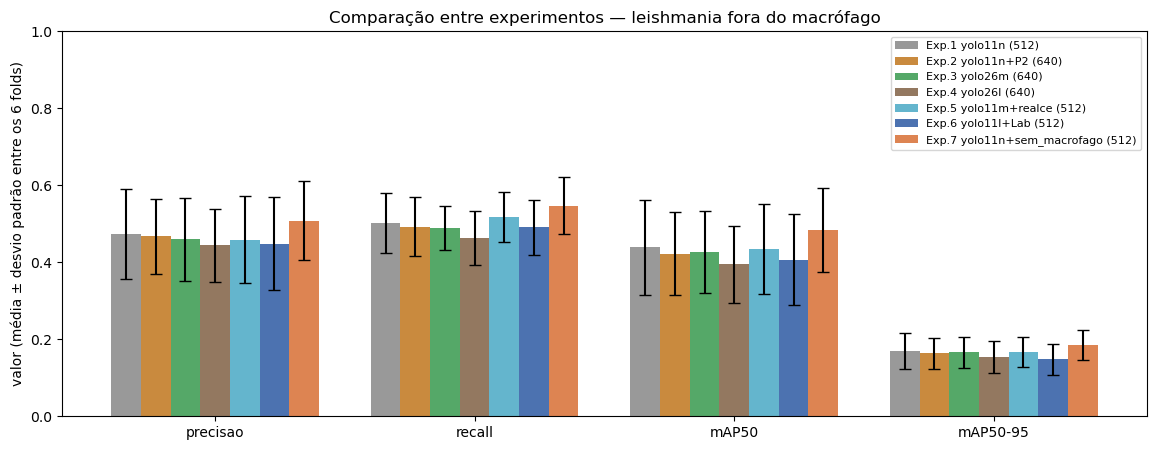

In [14]:
%matplotlib inline
# Médias e desvios padrão dos experimentos anteriores, copiados aqui apenas para referência visual.
# Exp.1-6 usaram os recortes ORIGINAIS (macrófago visível); apenas o Exp.7 (este) usa os recortes
# com a região do macrófago mascarada -- mesmas lâminas/folds/classe-alvo em todos.
resumo_experimentos_anteriores = {
    'Exp.1 yolo11n (512)': pd.Series({'precisao': 0.4735, 'recall': 0.5012, 'mAP50': 0.4391, 'mAP50-95': 0.1695}),
    'Exp.2 yolo11n+P2 (640)': pd.Series({'precisao': 0.4672, 'recall': 0.4922, 'mAP50': 0.4226, 'mAP50-95': 0.1640}),
    'Exp.3 yolo26m (640)': pd.Series({'precisao': 0.4595, 'recall': 0.4894, 'mAP50': 0.4272, 'mAP50-95': 0.1659}),
    'Exp.4 yolo26l (640)': pd.Series({'precisao': 0.4442, 'recall': 0.4632, 'mAP50': 0.3943, 'mAP50-95': 0.1538}),
    'Exp.5 yolo11m+realce (512)': pd.Series({'precisao': 0.4581, 'recall': 0.5170, 'mAP50': 0.4345, 'mAP50-95': 0.1670}),
    'Exp.6 yolo11l+Lab (512)': pd.Series({'precisao': 0.4485, 'recall': 0.4904, 'mAP50': 0.4067, 'mAP50-95': 0.1483}),
}
desvios_experimentos_anteriores = {
    'Exp.1 yolo11n (512)': pd.Series({'precisao': 0.1164, 'recall': 0.0780, 'mAP50': 0.1229, 'mAP50-95': 0.0457}),
    'Exp.2 yolo11n+P2 (640)': pd.Series({'precisao': 0.0981, 'recall': 0.0763, 'mAP50': 0.1083, 'mAP50-95': 0.0405}),
    'Exp.3 yolo26m (640)': pd.Series({'precisao': 0.1079, 'recall': 0.0567, 'mAP50': 0.1068, 'mAP50-95': 0.0396}),
    'Exp.4 yolo26l (640)': pd.Series({'precisao': 0.0946, 'recall': 0.0705, 'mAP50': 0.1000, 'mAP50-95': 0.0417}),
    'Exp.5 yolo11m+realce (512)': pd.Series({'precisao': 0.1132, 'recall': 0.0652, 'mAP50': 0.1175, 'mAP50-95': 0.0391}),
    'Exp.6 yolo11l+Lab (512)': pd.Series({'precisao': 0.1206, 'recall': 0.0707, 'mAP50': 0.1180, 'mAP50-95': 0.0407}),
}

metricas_plot = ['precisao', 'recall', 'mAP50', 'mAP50-95']
nomes_exp = list(resumo_experimentos_anteriores.keys()) + ['Exp.7 yolo11n+sem_macrofago (512)']
medias_exp = [resumo_experimentos_anteriores[n][metricas_plot] for n in resumo_experimentos_anteriores] + [resumo_metricas.loc[metricas_plot, 'média']]
desvios_exp = [desvios_experimentos_anteriores[n][metricas_plot] for n in desvios_experimentos_anteriores] + [resumo_metricas.loc[metricas_plot, 'desvio_padrão']]

x = np.arange(len(metricas_plot))
n_exp = len(nomes_exp)
largura = 0.8 / n_exp
cores = ['#999999', '#c98a3e', '#55a868', '#937860', '#64b5cd', '#4C72B0', '#dd8452']

fig, ax = plt.subplots(figsize=(14, 5))
for i, (nome, media, desvio) in enumerate(zip(nomes_exp, medias_exp, desvios_exp)):
    deslocamento = (i - (n_exp - 1) / 2) * largura
    ax.bar(x + deslocamento, media, largura, yerr=desvio, capsize=4, label=nome, color=cores[i % len(cores)])

ax.set_xticks(x)
ax.set_xticklabels(metricas_plot)
ax.set_ylim(0, 1)
ax.set_ylabel('valor (média ± desvio padrão entre os 6 folds)')
ax.set_title('Comparação entre experimentos — leishmania fora do macrófago')
ax.legend(loc='upper right', fontsize=8)
plt.show()


## Diagnóstico por lâmina (conjunto de teste)

In [15]:
linhas_metricas_lamina = []

for (n, lamina), caminho_yaml_lamina in caminhos_yaml_lamina.items():
    modelo = YOLO(caminhos_best[n])
    resultado = modelo.val(data=caminho_yaml_lamina, split='test', imgsz=tamanho_imagem, plots=False, verbose=False)

    metricas = extrai_metricas(resultado)
    metricas['fold'] = n
    metricas['lamina'] = lamina
    linhas_metricas_lamina.append(metricas)

df_metricas_lamina = pd.DataFrame(linhas_metricas_lamina)[['lamina', 'fold', 'precisao', 'recall', 'mAP50', 'mAP50-95']]
df_metricas_lamina.sort_values(['lamina', 'fold']).reset_index(drop=True)


Ultralytics 8.4.75 🚀 Python-3.13.9 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 15842MiB)


YOLO11n summary (fused): 101 layers, 2,582,347 parameters, 0 gradients, 6.3 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3722.9±236.2 MB/s, size: 219.9 KB)


val: Scanning /mnt/arquivos/Doutorado/yolo_folds_leishmania_sem_macrofago/fold_1/labels/test_lamina/leish_3... 17 images, 11 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 17/17 4.8Kit/s 0.0s

val: New cache created: /mnt/arquivos/Doutorado/yolo_folds_leishmania_sem_macrofago/fold_1/labels/test_lamina/leish_3.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 20.0it/s 0.1s

... (118 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 45.0it/s 0.5s

                   all        353        992       0.39      0.464      0.339      0.129


Speed: 0.2ms preprocess, 0.5ms inference, 0.0ms loss, 0.2ms postprocess per image


,lamina,fold,precisao,recall,mAP50,mAP50-95
0,leish_1,3,0.676382,0.394873,0.486417,0.213485
1,leish_1,5,0.717357,0.445247,0.564424,0.251071
2,leish_2,2,0.402189,0.512436,0.391146,0.142762
3,leish_2,6,0.390178,0.537383,0.406818,0.153129
4,leish_3,1,0.384671,0.600000,0.359131,0.141821
5,leish_4,4,0.345989,0.234848,0.184396,0.082495
6,leish_5,1,0.551107,0.573968,0.536150,0.175902
7,leish_7,2,0.669990,0.645642,0.667967,0.250972
8,leish_7,5,0.681582,0.655716,0.676135,0.254283
9,leish_8,3,0.412364,0.453440,0.378212,0.149544


In [16]:
# Resumo por lâmina: média e desvio padrão entre as vezes em que a lâmina caiu no teste (1 ou 2 folds)
resumo_lamina = df_metricas_lamina.groupby('lamina')[['precisao', 'recall', 'mAP50', 'mAP50-95']].agg(['mean', 'std', 'count'])
resumo_lamina.round(4)


precisao                recall                 mAP50                \
            mean     std count    mean     std count    mean     std count   
lamina                                                                       
leish_1   0.6969  0.0290     2  0.4201  0.0356     2  0.5254  0.0552     2   
leish_2   0.3962  0.0085     2  0.5249  0.0176     2  0.3990  0.0111     2   
leish_3   0.3847     NaN     1  0.6000     NaN     1  0.3591     NaN     1   
leish_4   0.3460     NaN     1  0.2348     NaN     1  0.1844     NaN     1   
leish_5   0.5511     NaN     1  0.5740     NaN     1  0.5362     NaN     1   
leish_7   0.6758  0.0082     2  0.6507  0.0071     2  0.6721  0.0058     2   
leish_8   0.4012  0.0158     2  0.4586  0.0073     2  0.3589  0.0274     2   
leish_9   0.5493     NaN     1  0.6657     NaN     1  0.5901     NaN     1   

        mAP50-95                
            mean     std count  
lamina                          
leish_1   0.2323  0.0266     2  
leish_2   0.1479  0.0073     2  
leish_3   0.1418     NaN     1  
leish_4   0.0825     NaN     1  
leish_5   0.1759     NaN     1  
leish_7   0.2526  0.0023     2  
leish_8   0.1393  0.0145     2  
leish_9   0.2465     NaN     1

## Comparação visual: anotação do especialista vs. detecção da YOLO

Em cada imagem: caixas **amarelas** = anotação original do especialista (classe `leishmania`, remapeada); caixas **vermelhas** = detecções do modelo (com confiança). Amostras da lâmina com melhor e da lâmina com pior mAP50 no diagnóstico acima. Imagens em RGB puro (região do macrófago aparece preta, mascarada no pré-processamento).

In [17]:
# Lê as caixas (em pixels) de um .txt YOLO (classe única já remapeada)
def le_boxes_pixel(txt_path, largura, altura):
    boxes = []
    if os.path.isfile(txt_path):
        with open(txt_path) as f:
            for linha in f:
                linha = linha.strip()
                if not linha:
                    continue
                _, xc, yc, w, h = map(float, linha.split())
                boxes.append((xc * largura, yc * altura, w * largura, h * altura))
    return boxes


# Desenha, sobre o mesmo eixo, as caixas do especialista (amarelo) e as detecções do modelo (vermelho)
def desenha_comparacao(eixo, caminho_imagem, caminho_label, modelo, conf=0.25):
    img_bgr = cv2.imread(caminho_imagem)
    altura, largura = img_bgr.shape[:2]
    eixo.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))

    gt_boxes = le_boxes_pixel(caminho_label, largura, altura)
    for xc, yc, w, h in gt_boxes:
        eixo.add_patch(patches.Rectangle((xc - w / 2, yc - h / 2), w, h, linewidth=1.5, edgecolor='yellow', facecolor='none'))

    resultado = modelo.predict(caminho_imagem, conf=conf, imgsz=tamanho_imagem, verbose=False)[0]
    for caixa in resultado.boxes:
        x1, y1, x2, y2 = caixa.xyxy[0].tolist()
        confianca = float(caixa.conf[0])
        eixo.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=1.5, edgecolor='red', facecolor='none'))
        eixo.text(x1, max(y1 - 4, 0), f"{confianca:.2f}", color='red', fontsize=7, va='bottom')

    eixo.set_title(f"{os.path.basename(caminho_imagem)}\nespecialista={len(gt_boxes)} | YOLO={len(resultado.boxes)}", fontsize=8)
    eixo.axis('off')


def fold_para_lamina(lamina):
    for fold in folds:
        if lamina in fold['teste']:
            return fold['fold']


Melhor lâmina (mAP50): leish_7 | Pior lâmina (mAP50): leish_4


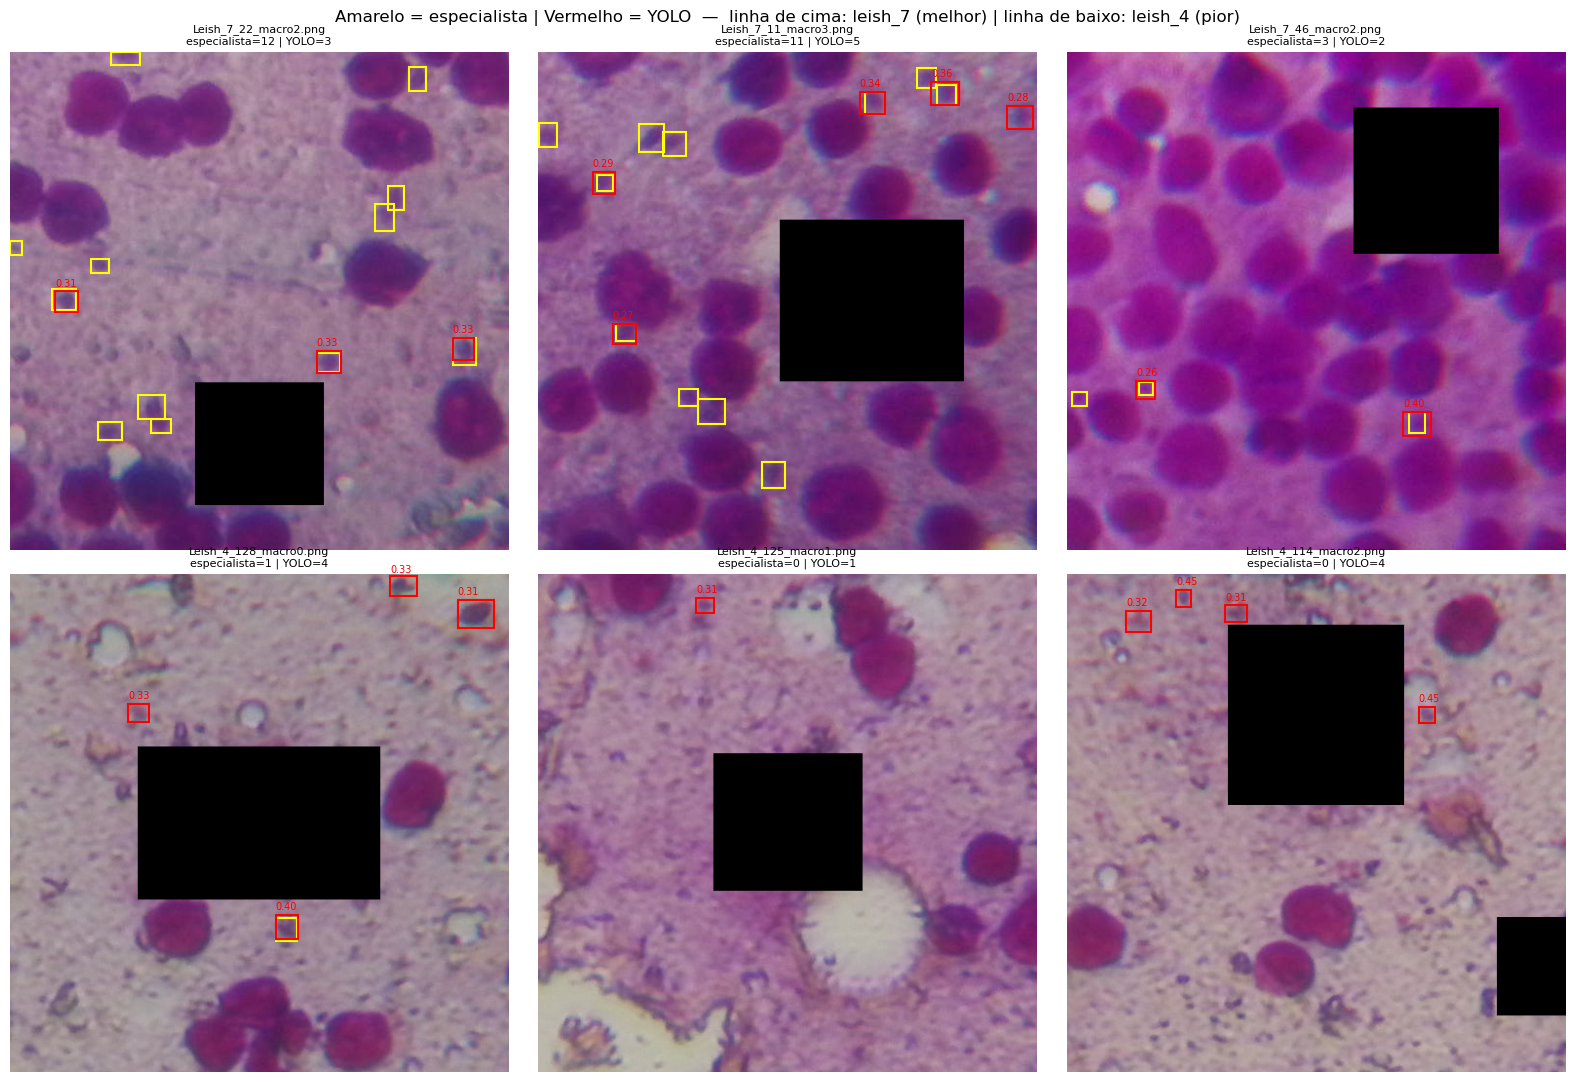

In [18]:
%matplotlib inline
melhor_lamina = resumo_lamina[('mAP50', 'mean')].idxmax()
pior_lamina = resumo_lamina[('mAP50', 'mean')].idxmin()
print(f"Melhor lâmina (mAP50): {melhor_lamina} | Pior lâmina (mAP50): {pior_lamina}")

cache_modelos = {}
def obter_modelo(n_fold):
    if n_fold not in cache_modelos:
        cache_modelos[n_fold] = YOLO(caminhos_best[n_fold])
    return cache_modelos[n_fold]

amostras_comparacao = []
random.seed(42)
for lamina in [melhor_lamina, pior_lamina]:
    n_fold = fold_para_lamina(lamina)
    pasta_img = os.path.join(diretorio_yolo_folds, f"fold_{n_fold}", 'images', 'test_lamina', lamina)
    pasta_lbl = os.path.join(diretorio_yolo_folds, f"fold_{n_fold}", 'labels', 'test_lamina', lamina)
    imagens = sorted(f for f in os.listdir(pasta_img) if f.endswith(extensao))
    escolhidas = random.sample(imagens, min(3, len(imagens)))
    for img_nome in escolhidas:
        amostras_comparacao.append((n_fold, lamina, pasta_img, pasta_lbl, img_nome))

fig, eixos = plt.subplots(2, 3, figsize=(16, 11))
for eixo, (n_fold, lamina, pasta_img, pasta_lbl, img_nome) in zip(eixos.ravel(), amostras_comparacao):
    modelo = obter_modelo(n_fold)
    nome_base = os.path.splitext(img_nome)[0]
    desenha_comparacao(eixo, os.path.join(pasta_img, img_nome), os.path.join(pasta_lbl, f"{nome_base}.txt"), modelo)

fig.suptitle(f"Amarelo = especialista | Vermelho = YOLO  —  linha de cima: {melhor_lamina} (melhor) | linha de baixo: {pior_lamina} (pior)")
plt.tight_layout()
plt.show()
